# WY2021 radar-site SNOWPACK comparison with TopoPyScale

Compare raw and lapse-rate HRRR-AK with the **1,000 m and 500 m TopoPyScale** simulations at DG1, TKG4, TKG3, TKG2, and C161. The new simulations use the original site configurations and raw WY2020 spin-up, then switch forcing on October 1, 2020 UTC. See [the forcing comparison](05_compare_WY2021_topopyscale_forcing.ipynb) for the actual SMET inputs.

The plots and tables use the same definitions as [notebook 02](02_compare_model_pit_radar_WY2021.ipynb). Solid depth curves subtract the minimum modeled depth in August–October 2020, a fixed reference for approximating seasonal snow. The opening figure shows full-record modeled depth, including spin-up. The WY2021 comparison shows adjusted seasonal depth. Model SWE includes the full snow/firn column, while pit SWE covers seasonal snow. Radar SWE uses prescribed density.

Pit depth and SWE use archived sampling dates. TKG4 uses July 7 for pit depth and July 8 for pit SWE. Radar uses the documented days for TKG3, TKG4, and C161. The horizontal bars retain the July 9–15 measurement window for TKG2 and DG1, whose exact radar dates are unresolved. Radar samples are selected within 500 m of each pit, and radar error bars show spatial percentiles. Model day and window means use UTC. These comparisons are descriptive.

## Figure settings

In [1]:
# Editable plotting settings for every figure in this notebook.
colors = {
    'hrrrak': 'maroon',
    'hrrrak_lapserate': 'royalblue',
    'topopyscale_1000m': '#bd5e22',
    'topopyscale_500m': '#00747a',
}
SIMULATION_LINEWIDTH = 2.2  # Full-record depth and SWE.
ADJUSTED_LINEWIDTH = 2.2    # Solid autumn-minimum-adjusted seasonal depth.
MATCH_Y_AXES = True       # Match limits within each figure; depth/SWE stay separate.


In [2]:
from pathlib import Path
import sys
import json
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path.cwd()/'jif_snow_modeling']
             if (p/'sites/radar_sites/scripts/prepare_radar_site_forcing.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open from inside jif_snow_modeling')
sys.path.insert(0, str(ROOT/'sites/radar_sites/scripts'))
from visualization import (SIMULATION_LABELS, OBSERVATION_COLOR,
    OBSERVATION_MARKERS, RC_PARAMS, comparison_legend)
from matplotlib.lines import Line2D
plt.rcParams.update(RC_PARAMS)
# Refresh dependencies so an older kernel cannot retain the four-site list.
import prepare_radar_site_forcing as forcing_module
import compare_model_pit_radar as comparison_module
importlib.reload(forcing_module)
importlib.reload(comparison_module)
load_comparison = comparison_module.load_comparison
runs = {
    'hrrrak': ('WY2020-WY2026', '2026-09-29T04:00'),
    'hrrrak_lapserate': ('WY2020-WY2026', '2026-09-29T04:00'),
    'topopyscale_1000m': ('WY2021', '2021-09-30T23:00'),
    'topopyscale_500m': ('WY2021', '2021-09-30T23:00'),
}
FORCINGS = tuple(runs)
labels = {**SIMULATION_LABELS, 'topopyscale_1000m': 'TopoPyScale 1,000 m',
          'topopyscale_500m': 'TopoPyScale 500 m'}
RADAR_WINDOWS = comparison_module.RADAR_WINDOWS
RADIUS_M = 500
result = load_comparison(radius=RADIUS_M, runs=runs)
pits=result['pits'];models=result['models'];adjusted=result['adjusted'];local=result['local_radar']
# Derive plotted sites from the loaded runs and check none were omitted.
SITES = tuple(dict.fromkeys(site for site, forcing in models))
if set(SITES) != set(forcing_module.SITES):
    raise RuntimeError('Loaded model sites do not match the configured sites; review the run audit.')
# Row-major subplot order follows configured model elevation, low to high.
from prepare_radar_site_forcing import MODEL_ROOT, PERIOD
elevations = {}
for site in SITES:
    metadata_path = MODEL_ROOT/site/'input'/f'hrrrak_{PERIOD}'/f'hrrrak_{site}_{PERIOD}.json'
    elevations[site] = json.loads(metadata_path.read_text())['elevation_m']
SITES = tuple(sorted(SITES, key=lambda site: (elevations[site], site)))
print(f'Loaded {len(SITES)} sites; subplot order: '+ ' → '.join(site.upper() for site in SITES))
display(pd.Series({site.upper(): elevations[site] for site in SITES}, name='Model elevation (m)'))
display(result['run_audit'])
display(pits[['pit_date','pit_swe_date','elevation_m','depth_cm','swe_mm','quality_flags']])
display(result['radius_sensitivity'].round(2))


Loaded 5 sites; subplot order: DG1 → TKG4 → TKG3 → TKG2 → C161


DG1     1018.0
TKG4    1120.0
TKG3    1203.0
TKG2    1326.0
C161    1483.0
Name: Model elevation (m), dtype: float64

,site,forcing,start_UTC,end_UTC,rows,path,numerical_guard
0,tkg2,hrrrak,2019-10-01 05:00:00,2026-09-29 04:00:00,61320,/home/cassie/python/models/run_snowpack/sites/...,None
1,tkg2,hrrrak_lapserate,2019-10-01 05:00:00,2026-09-29 04:00:00,61320,/home/cassie/python/models/run_snowpack/sites/...,None
2,tkg2,topopyscale_1000m,2019-10-01 05:00:00,2021-09-30 23:00:00,17539,/home/cassie/python/models/run_snowpack/sites/...,None
3,tkg2,topopyscale_500m,2019-10-01 05:00:00,2021-09-30 23:00:00,17539,/home/cassie/python/models/run_snowpack/sites/...,None
4,tkg3,hrrrak,2019-10-01 05:00:00,2026-09-29 04:00:00,61320,/home/cassie/python/models/run_snowpack/sites/...,None
5,tkg3,hrrrak_lapserate,2019-10-01 05:00:00,2026-09-29 04:00:00,61320,/home/cassie/python/models/run_snowpack/sites/...,None
6,tkg3,topopyscale_1000m,2019-10-01 05:00:00,2021-09-30 23:00:00,17539,/home/cassie/python/models/run_snowpack/sites/...,None
7,tkg3,topopyscale_500m,2019-10-01 05:00:00,2021-09-30 23:00:00,17539,/home/cassie/python/models/run_snowpack/sites/...,None
8,c161,hrrrak,2019-10-01 05:00:00,2026-09-29 04:00:00,61320,/home/cassie/python/models/run_snowpack/sites/...,None
9,c161,hrrrak_lapserate,2019-10-01 05:00:00,2026-09-29 04:00:00,61320,/home/cassie/python/models/run_snowpack/sites/...,None


,pit_date,pit_swe_date,elevation_m,depth_cm,swe_mm,quality_flags
site,,,,,,
tkg2,2021-07-15,2021-07-15,1326.0,360.0,2086.1,
tkg3,2021-07-09,2021-07-09,1203.0,378.0,2110.3,archived_pit_date_differs_from_paper_table1_gt...
c161,2021-07-15,2021-07-15,1483.0,473.0,2776.8,
tkg4,2021-07-07,2021-07-08,1067.0,378.0,2014.3,archived_pit_date_differs_from_paper_table1_gt...
dg1,2021-07-10,2021-07-10,1018.0,315.0,1759.4,


,site,radius_m,rows,rejected_rows,exact_duplicate_rows,profiles,depth_cm_p10,depth_cm_median,depth_cm_p90,swe_mm_p10,swe_mm_median,swe_mm_p90
0,tkg2,100,361,1,0,"NWBN,NWBS",278.73,361.59,375.18,1516.43,1988.28,2066.09
1,tkg2,250,736,1,0,"NWBN,NWBS",278.73,360.23,372.46,1516.43,1980.50,2050.51
2,tkg2,500,1340,1,0,"NWBN,NWBS",278.73,358.87,379.25,1516.43,1972.73,2089.47
3,tkg2,1000,2577,1,0,"NWBN,NWBS",278.73,364.31,381.97,1516.43,2003.84,2105.06
4,tkg2,2000,5110,1,0,"NWBN,NWBS",290.96,368.39,394.20,1585.72,2027.19,2175.23
5,tkg3,100,325,3,4,"Matthes-Taku,NWBS",280.09,284.17,290.96,1524.13,1547.23,1585.72
6,tkg3,250,708,3,4,"Matthes-Taku,NWBS",280.09,282.81,289.60,1524.13,1539.53,1578.05
7,tkg3,500,1328,3,4,"Matthes-Taku,NWBS",278.73,282.81,288.25,1516.43,1539.53,1570.35
8,tkg3,1000,2577,3,4,"Matthes-Taku,NWBS",276.02,282.81,286.89,1501.09,1539.53,1562.64
9,tkg3,2000,5090,3,4,"Matthes-Taku,NWBS",274.66,285.53,326.28,1493.39,1554.93,1786.58


## Full modeled snow-depth record

Daily mean total snow and firn depth for each run, from its start through its final modeled hour. The TopoPyScale cases share the raw HRRR-AK spin-up and end in September 2021. The raw and lapse-rate HRRR-AK records continue into September 2026. Shading marks WY2021, which is shown separately below.


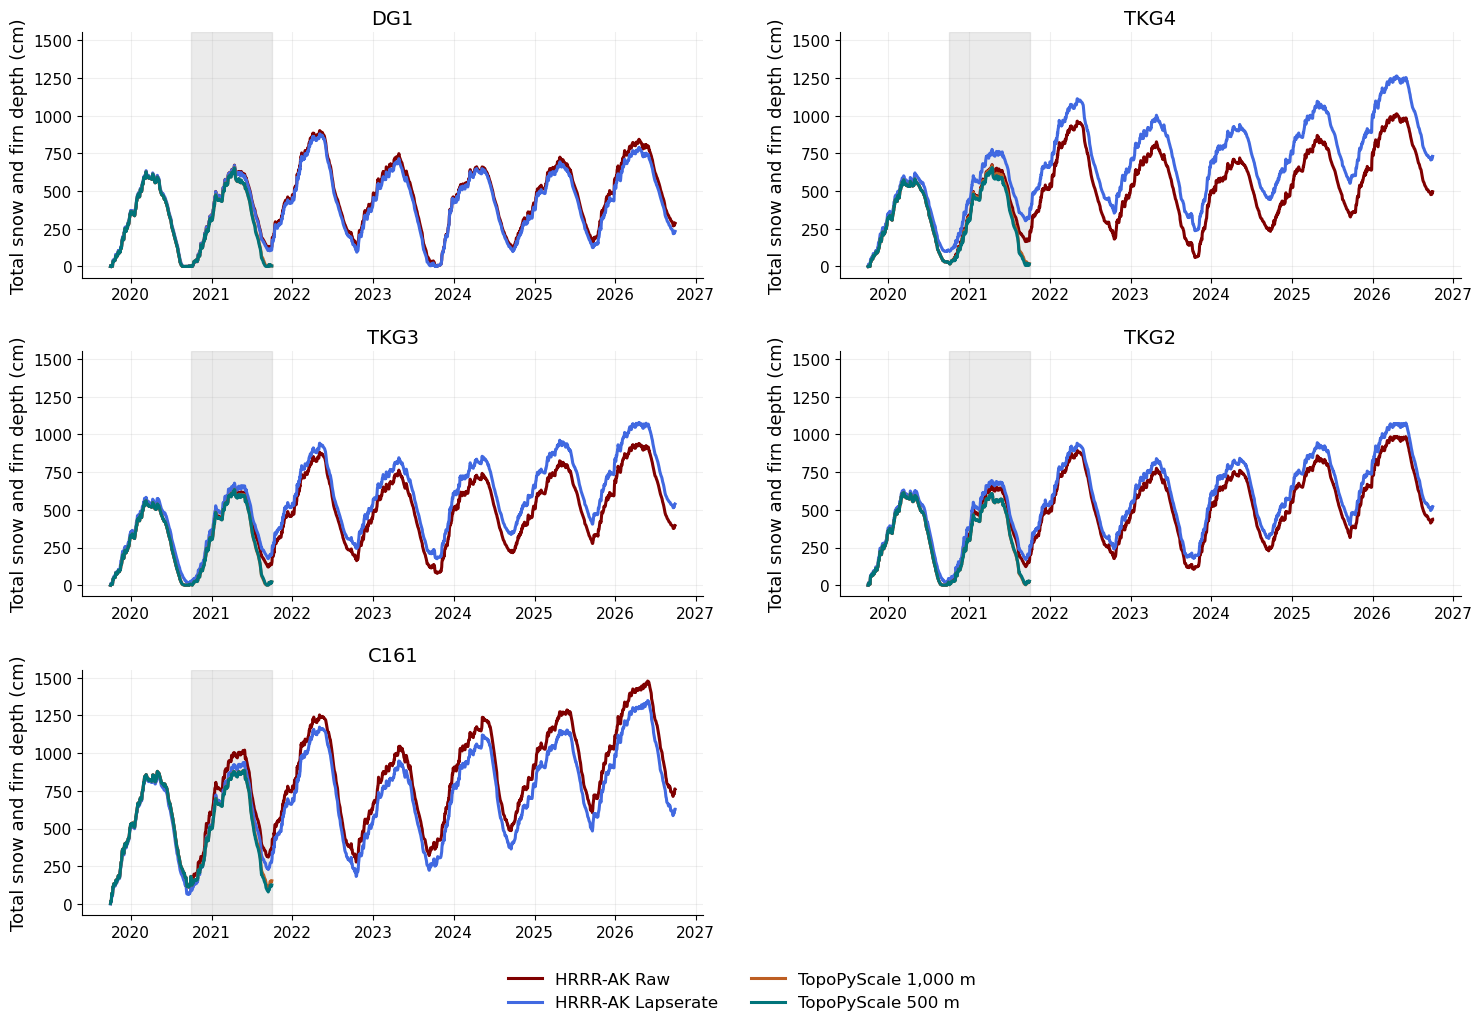

In [3]:
rows = (len(SITES) + 1) // 2
fig, axes = plt.subplots(rows, 2, figsize=(15, 3.5*rows), sharex=True,
                         sharey=MATCH_Y_AXES, squeeze=False)
start, end = pd.Timestamp('2020-10-01'), pd.Timestamp('2021-10-01')
for ax, site in zip(axes.flat, SITES):
    for forcing in FORCINGS:
        daily = models[site, forcing].depth_cm.resample('D').mean()
        ax.plot(daily.index, daily, color=colors[forcing], lw=SIMULATION_LINEWIDTH)
    ax.axvspan(start, end, color='0.65', alpha=.22, zorder=0)
    ax.set(title=site.upper(), ylabel='Total snow and firn depth (cm)')
    ax.tick_params(axis='both', labelbottom=True, labelleft=True)
    ax.grid(alpha=.2)
for ax in axes.flat[len(SITES):]:
    ax.set_visible(False)
locator = mdates.AutoDateLocator()
axes[0,0].xaxis.set_major_locator(locator)
axes[0,0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
handles = [Line2D([], [], color=colors[f], lw=SIMULATION_LINEWIDTH, label=labels[f])
           for f in FORCINGS]
fig.tight_layout(rect=(0,.09,1,1))
comparison_legend(fig, handles, columns=2, bottom=.12)
plt.show()


## WY2021 depth and SWE

The figure starts on October 1, 2020 UTC. Depth uses the autumn-minimum seasonal approximation. SWE represents the total modeled column. Negative adjusted depths remain visible. Black circles show the original pit observations. Black squares show radar medians; vertical bars are spatial 10th–90th percentiles, and horizontal bars identify unresolved acquisition windows. Model time series remain visible through the window rather than selecting an arbitrary radar date.

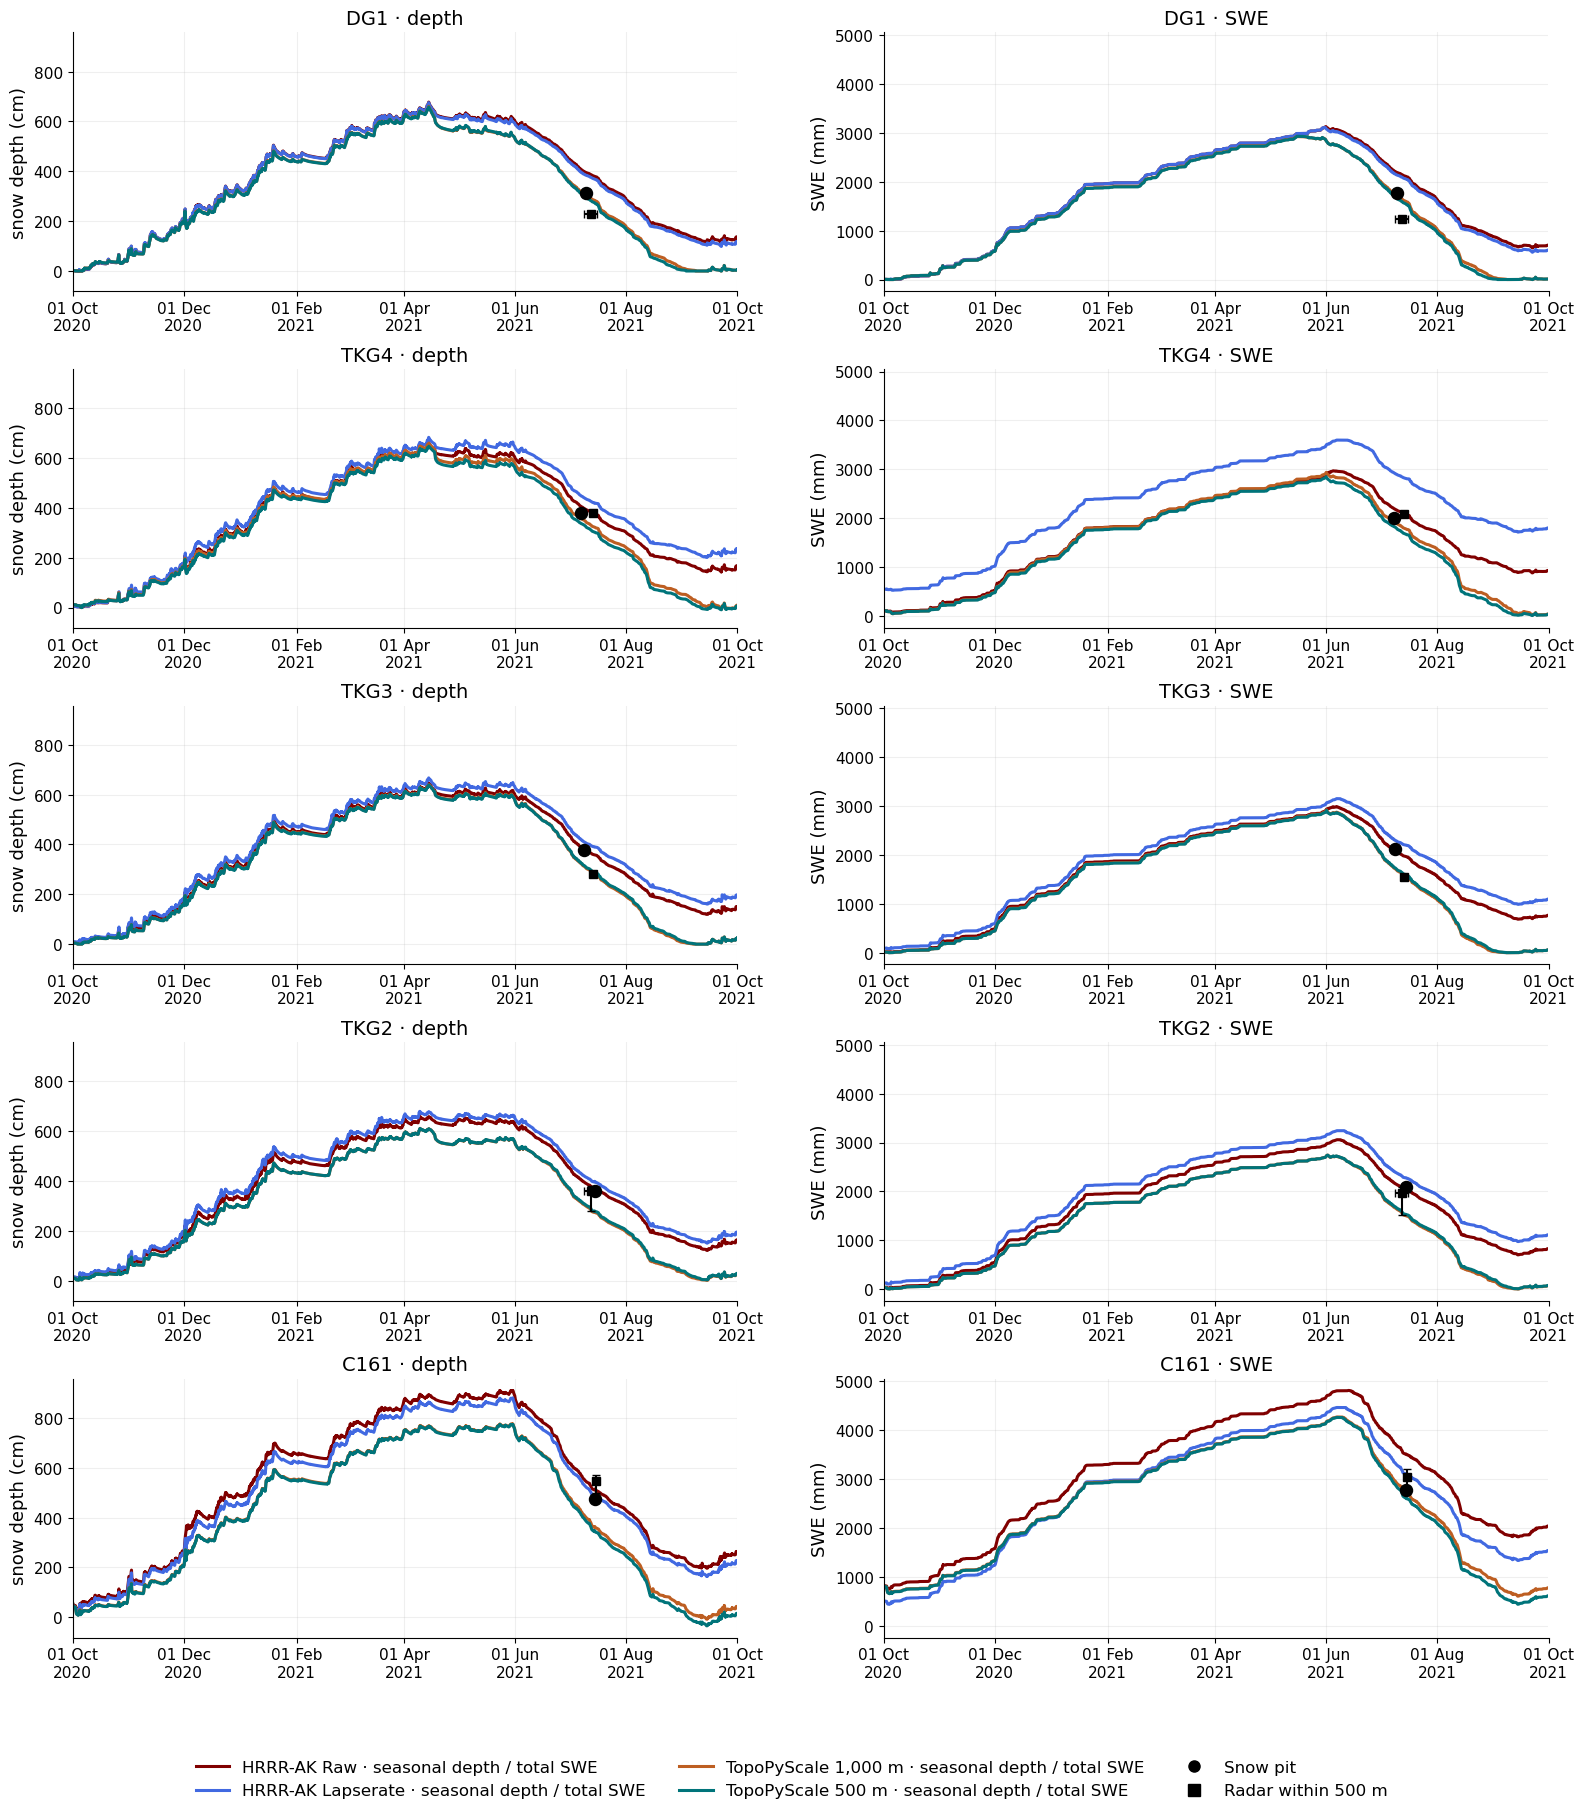

In [4]:
fig,axes=plt.subplots(len(SITES),2,figsize=(16,3.7*len(SITES)),sharex=True,sharey='col' if MATCH_Y_AXES else False)
for i,site in enumerate(SITES):
    pit=pits.loc[site]
    for forcing in FORCINGS:
        frame=adjusted[(site,forcing)].loc['2020-10-01':'2021-09-30']
        axes[i,0].plot(frame.index,frame.depth_above_minimum_cm,color=colors[forcing],ls='-',lw=ADJUSTED_LINEWIDTH,label=labels[forcing]+' · minus autumn minimum')
        axes[i,1].plot(frame.index,frame.swe_mm,color=colors[forcing],lw=SIMULATION_LINEWIDTH,label=labels[forcing])
    for j,(column,scale,pit_value,label) in enumerate([
        ('aa_avg_depth_m',100,pit.depth_cm,'snow depth (cm)'),
        ('aa_swe_avg_m',1000,pit.swe_mm,'SWE (mm)')]):
        ax=axes[i,j]
        ax.scatter(pit.pit_date if j==0 else pit.pit_swe_date,pit_value,c=OBSERVATION_COLOR,marker=OBSERVATION_MARKERS['pit'],s=75,zorder=6,label='Archived pit')
        samples=local[site]
        if len(samples):
            q=samples[column].quantile([.1,.5,.9])*scale
            start,end=map(pd.Timestamp,RADAR_WINDOWS[site])
            # Known radar days are plotted at noon; TKG2 and DG1 span the campaign.
            midpoint=start+(end-start)/2
            xerr=np.array([[(end-start)/pd.Timedelta(days=2)]]) if site in {'tkg2','dg1'} else None
            ax.errorbar(mdates.date2num(midpoint),q.loc[.5],yerr=[[q.loc[.5]-q.loc[.1]],[q.loc[.9]-q.loc[.5]]],
                        xerr=xerr,fmt=OBSERVATION_MARKERS['radar'],color=OBSERVATION_COLOR,capsize=3,zorder=5,label=f'Radar within {RADIUS_M} m')
        ax.set(title=f'{site.upper()} · '+('depth' if j==0 else 'SWE'),ylabel=label,
               xlim=(pd.Timestamp('2020-10-01'),pd.Timestamp('2021-10-01')))
        ax.tick_params(axis='x',labelbottom=True)
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[10,12,2,4,6,8],bymonthday=1));ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%Y'))
        ax.grid(alpha=.2)
for ax in axes.flat[:len(SITES)] if axes.shape[0] != len(SITES) else axes.flat:
    if ax.get_visible(): ax.tick_params(axis='y',labelleft=True)
fig.tight_layout(rect=(0,.10,1,1))
handles=[Line2D([],[],color=colors[f],lw=ADJUSTED_LINEWIDTH,label=labels[f]+' · seasonal depth / total SWE') for f in FORCINGS]
handles += [Line2D([],[],color=OBSERVATION_COLOR,marker=OBSERVATION_MARKERS['pit'],ls='',markersize=8,label='Snow pit'),
            Line2D([],[],color=OBSERVATION_COLOR,marker=OBSERVATION_MARKERS['radar'],ls='',markersize=8,label=f'Radar within {RADIUS_M} m')]
comparison_legend(fig,handles,columns=3,bottom=.11)
plt.show()


## Seasonal snow depth around the observations

The same five panels share a date window extending three days before the earliest observation and three days after the latest radar window. The depth limits use the model and observation values in this view.

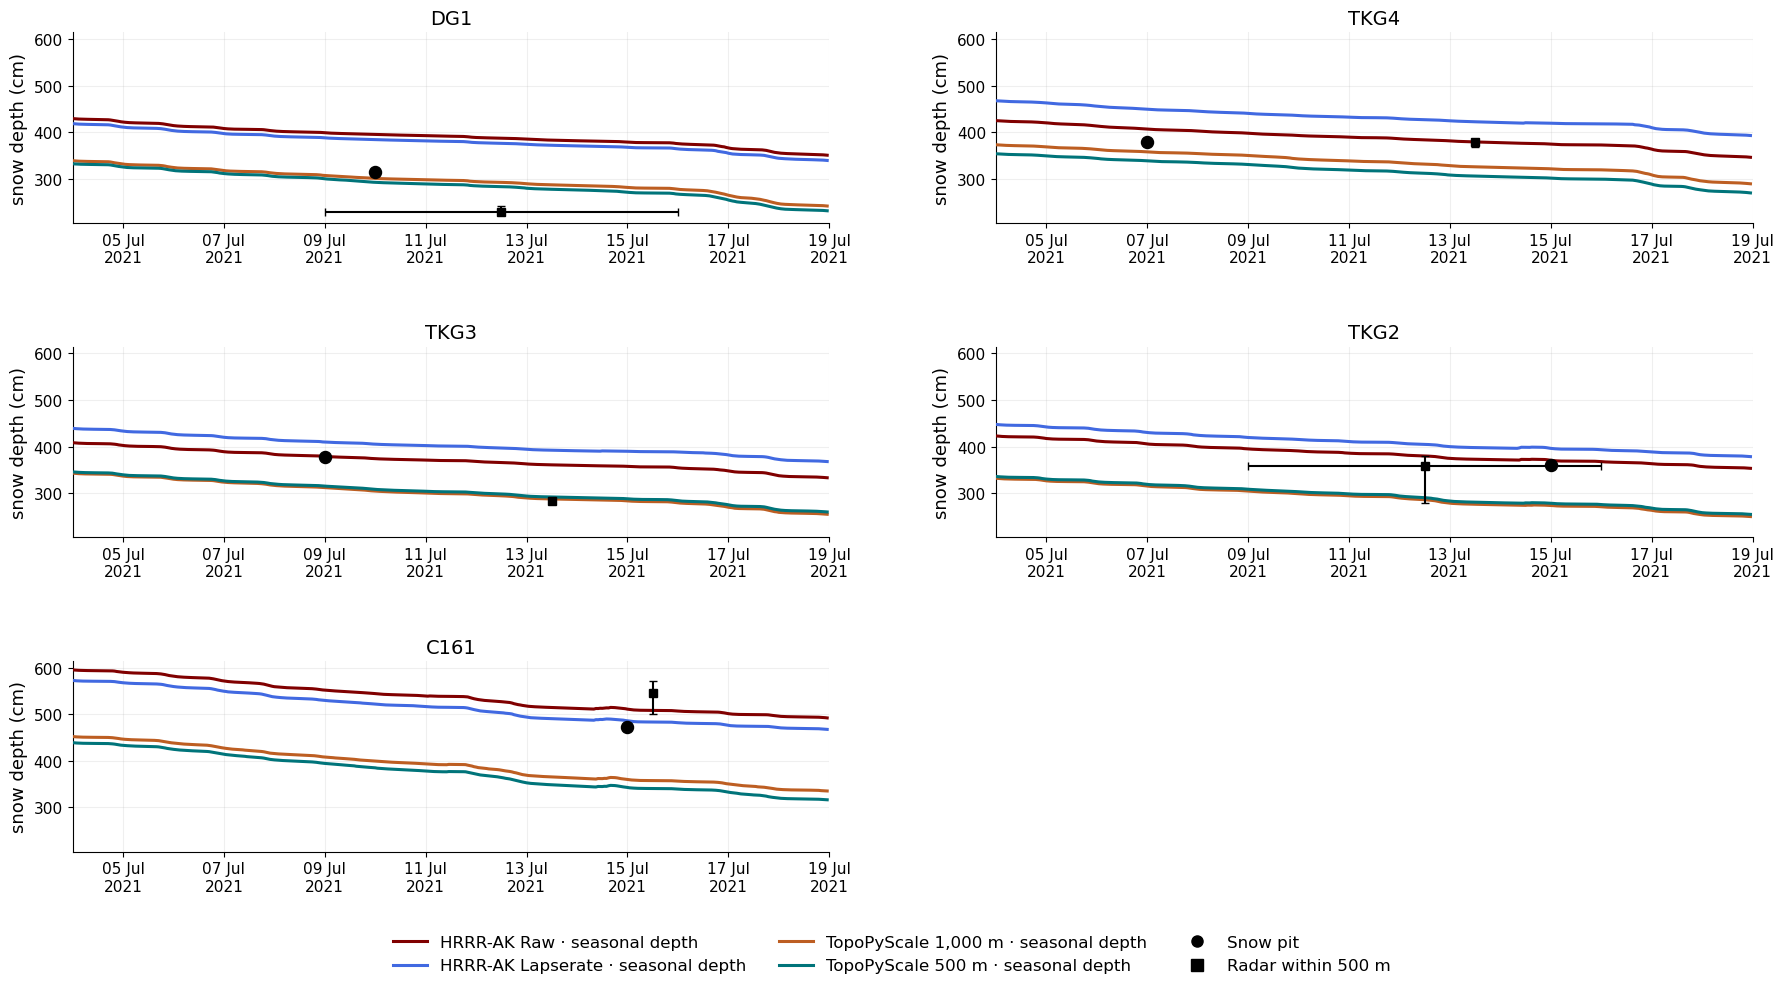

In [5]:
def plot_presentation_depth(*, zoom_days=None):
    start_date = pd.Timestamp('2020-10-01')
    end_date = pd.Timestamp('2021-10-01')
    if zoom_days is not None:
        observation_dates = list(pd.to_datetime(pits.loc[list(SITES), 'pit_date']))
        for site in SITES:
            if len(local[site]):
                observation_dates.extend(map(pd.Timestamp, RADAR_WINDOWS[site]))
        padding = pd.Timedelta(days=zoom_days)
        start_date = min(observation_dates).normalize() - padding
        end_date = max(observation_dates).normalize() + padding
    fig_depth,depth_axes=plt.subplots(3,2,figsize=(18,10.125),sharex=True,sharey=MATCH_Y_AXES)
    for ax,site in zip(depth_axes.flat,SITES):
        pit=pits.loc[site]
        for forcing in FORCINGS:
            frame=adjusted[(site,forcing)].loc[start_date:end_date-pd.Timedelta(nanoseconds=1)]
            ax.plot(frame.index,frame.depth_above_minimum_cm,color=colors[forcing],
                    lw=ADJUSTED_LINEWIDTH,ls='-',zorder=3)
        ax.scatter(pit.pit_date,pit.depth_cm,c=OBSERVATION_COLOR,
                   marker=OBSERVATION_MARKERS['pit'],s=75,zorder=6)
        samples=local[site]
        if len(samples):
            q=samples.aa_avg_depth_m.quantile([.1,.5,.9])*100
            start,end=map(pd.Timestamp,RADAR_WINDOWS[site])
            midpoint=start+(end-start)/2
            xerr=np.array([[(end-start)/pd.Timedelta(days=2)]]) if site in {'tkg2','dg1'} else None
            ax.errorbar(mdates.date2num(midpoint),q.loc[.5],
                        yerr=[[q.loc[.5]-q.loc[.1]],[q.loc[.9]-q.loc[.5]]],xerr=xerr,
                        fmt=OBSERVATION_MARKERS['radar'],color=OBSERVATION_COLOR,capsize=3,zorder=5)
        ax.set(title=site.upper(),ylabel='snow depth (cm)',xlabel='',
               xlim=(start_date,end_date))
        if zoom_days is None:
            locator=mdates.MonthLocator(bymonth=[10,12,2,4,6,8],bymonthday=1)
        else:
            locator=mdates.DayLocator(interval=2)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%Y'))
        ax.tick_params(axis='x',labelbottom=True)
        ax.grid(alpha=.2)
    for ax in depth_axes.flat[len(SITES):]: ax.set_visible(False)
    for ax in depth_axes.flat[:len(SITES)]: ax.tick_params(axis='y',labelleft=True)
    fig_depth.tight_layout(rect=(0,.12,1,1))
    handles=[Line2D([],[],color=colors[f],lw=ADJUSTED_LINEWIDTH,label=labels[f]+' · seasonal depth') for f in FORCINGS]
    handles += [Line2D([],[],color=OBSERVATION_COLOR,marker=OBSERVATION_MARKERS['pit'],ls='',markersize=8,label='Snow pit'),
                Line2D([],[],color=OBSERVATION_COLOR,marker=OBSERVATION_MARKERS['radar'],ls='',markersize=8,label=f'Radar within {RADIUS_M} m')]
    comparison_legend(fig_depth,handles,columns=3,bottom=.15)
    fig_depth.subplots_adjust(hspace=.65)
    return fig_depth, depth_axes


fig_observations, observation_axes = plot_presentation_depth(zoom_days=3)
plt.show()

## Snow-depth summary statistics

Compare the **autumn-minimum-adjusted model depth** (solid lines) with the archived pit depth and the median radar depth within 500 m. Positive model-minus-observation values mean the model is deeper; negative values mean it is shallower. All depths and differences are in **cm**.

Model depth is averaged over the pit's collection day for the pit comparison, and over the radar day/window for the radar comparison. TKG2 and DG1 retain the July 9–15 campaign window because their exact radar dates are unresolved. Therefore separate model values are shown for the two observation windows.

Mean absolute difference (MAE) summarizes the magnitude without allowing overestimates and underestimates to cancel. Mean signed difference (bias) retains their direction. Each site/forcing/source comparison receives equal weight, regardless of the number of radar samples. These are descriptive discrepancies for a fixed-baseline seasonal-depth approximation; radar spatial spread is not an uncertainty bound on model error.

In [6]:
stats = comparison_module.snow_depth_statistics(result['comparisons'])
depth_summary = stats['detail'].copy()
depth_summary['site'] = pd.Categorical(depth_summary.site,categories=SITES,ordered=True)
depth_summary = depth_summary.sort_values(['site','forcing']).reset_index(drop=True)
depth_summary['simulation'] = depth_summary.forcing.map(labels)
depth_summary['radar_window'] = depth_summary.apply(
    lambda r: r.radar_window_start.strftime('%Y-%m-%d') if
    r.radar_window_end_exclusive-r.radar_window_start == pd.Timedelta(days=1) else
    r.radar_window_start.strftime('%Y-%m-%d')+'–'+
    (r.radar_window_end_exclusive-pd.Timedelta(days=1)).strftime('%Y-%m-%d'),axis=1)
columns = ['site','simulation','pit_date','pit_depth_cm','model_at_pit_cm','model_minus_pit_cm',
           'radar_window','radar_median_depth_cm','model_at_radar_cm','model_minus_radar_cm']
summary_display = depth_summary[columns].rename(columns={
    'site':'Site','simulation':'Simulation','pit_date':'Pit date','pit_depth_cm':'Pit (cm)',
    'model_at_pit_cm':'Model at pit date (cm)','model_minus_pit_cm':'Model − pit (cm)',
    'radar_window':'Radar date/window','radar_median_depth_cm':'Radar median (cm)',
    'model_at_radar_cm':'Model at radar window (cm)','model_minus_radar_cm':'Model − radar (cm)'})
summary_display['Site'] = summary_display['Site'].astype(str).str.upper()
formats={column:'{:.1f}' for column in summary_display.select_dtypes(include='number').columns}
formats.update({'Model − pit (cm)':'{:+.1f}','Model − radar (cm)':'{:+.1f}',
                'Pit date':lambda t:t.strftime('%Y-%m-%d')})
display(summary_display.style.format(formats).hide(axis='index'))

by_simulation = stats['by_simulation'].reset_index()
by_simulation['forcing'] = by_simulation.forcing.map(labels)
by_simulation['observation'] = by_simulation.observation.replace({'Pit depth':'Snow pit'})
by_simulation = by_simulation.rename(columns={'forcing':'Simulation','observation':'Observation',
    'comparisons':'Site comparisons','mean_bias_cm':'Mean bias (cm)',
    'mean_absolute_difference_cm':'Mean absolute difference (cm)'})
display(by_simulation.style.format({'Mean bias (cm)':'{:+.1f}',
    'Mean absolute difference (cm)':'{:.1f}'}).hide(axis='index'))


Site,Simulation,Pit date,Pit (cm),Model at pit date (cm),Model − pit (cm),Radar date/window,Radar median (cm),Model at radar window (cm),Model − radar (cm)
DG1,HRRR-AK Raw,2021-07-10,315.0,393.7,+78.7,2021-07-09–2021-07-15,229.6,387.1,+157.5
DG1,HRRR-AK Lapserate,2021-07-10,315.0,382.7,+67.7,2021-07-09–2021-07-15,229.6,376.0,+146.4
DG1,"TopoPyScale 1,000 m",2021-07-10,315.0,299.2,-15.8,2021-07-09–2021-07-15,229.6,291.8,+62.2
DG1,TopoPyScale 500 m,2021-07-10,315.0,290.5,-24.5,2021-07-09–2021-07-15,229.6,282.6,+53.0
TKG4,HRRR-AK Raw,2021-07-07,378.0,404.6,+26.6,2021-07-13,377.9,379.1,+1.2
TKG4,HRRR-AK Lapserate,2021-07-07,378.0,447.2,+69.2,2021-07-13,377.9,422.4,+44.5
TKG4,"TopoPyScale 1,000 m",2021-07-07,378.0,355.8,-22.2,2021-07-13,377.9,325.8,-52.1
TKG4,TopoPyScale 500 m,2021-07-07,378.0,336.5,-41.5,2021-07-13,377.9,305.9,-72.0
TKG3,HRRR-AK Raw,2021-07-09,378.0,376.6,-1.4,2021-07-13,282.8,360.8,+78.0
TKG3,HRRR-AK Lapserate,2021-07-09,378.0,407.7,+29.7,2021-07-13,282.8,392.2,+109.4


Simulation,Observation,Site comparisons,Mean bias (cm),Mean absolute difference (cm)
HRRR-AK Raw,Snow pit,5,+29.7,30.2
HRRR-AK Raw,Radar,5,+44.3,58.8
HRRR-AK Lapserate,Snow pit,5,+42.4,42.4
HRRR-AK Lapserate,Radar,5,+57.0,81.5
"TopoPyScale 1,000 m",Snow pit,5,-62.1,62.1
"TopoPyScale 1,000 m",Radar,5,-49.1,75.9
TopoPyScale 500 m,Snow pit,5,-69.5,69.5
TopoPyScale 500 m,Radar,5,-56.6,81.4


## Snow-depth differences by site

Bars to the left of zero show where the model is shallower than the observation. Bars to the right show where it is deeper. Each legend gives the mean absolute difference across sites for that forcing and observation source.

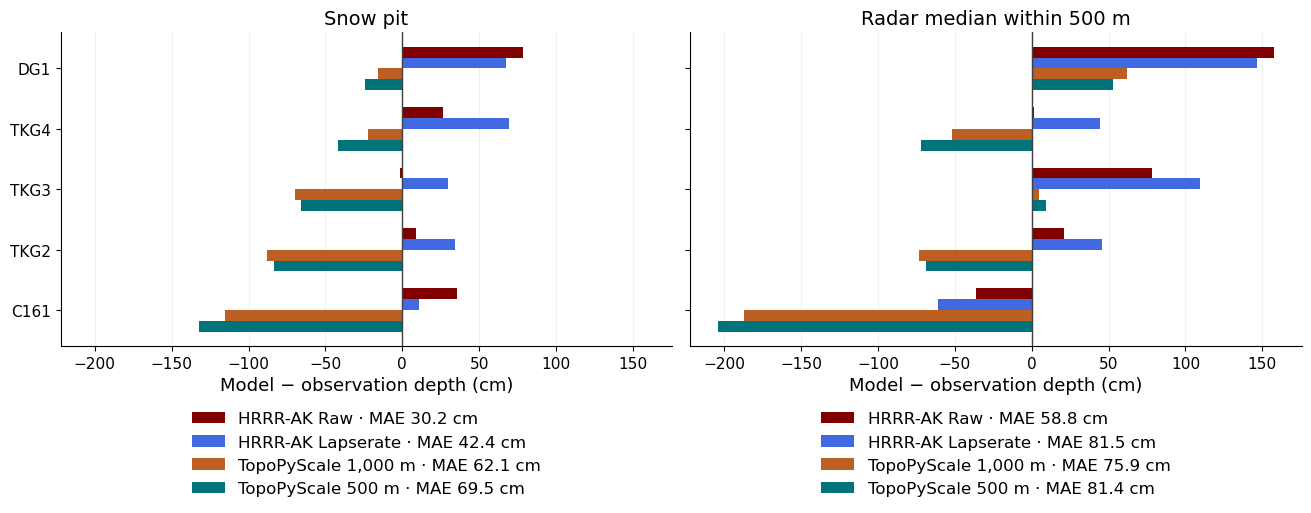

In [7]:
fig_depth_error, error_axes = plt.subplots(
    1, 2, figsize=(13, 5), sharex=True, sharey=True, layout='constrained'
)
positions = np.arange(len(SITES))
bar_height = 0.18

for ax, title, column in zip(
    error_axes,
    ('Snow pit', f'Radar median within {RADIUS_M} m'),
    ('model_minus_pit_cm', 'model_minus_radar_cm'),
):
    for offset, forcing in zip((np.arange(len(FORCINGS)) - (len(FORCINGS) - 1) / 2) * bar_height, FORCINGS):
        differences = (depth_summary.loc[depth_summary.forcing.eq(forcing)]
                       .set_index('site')[column].reindex(SITES))
        mae = differences.abs().mean()
        ax.barh(positions + offset, differences, height=bar_height,
                color=colors[forcing], label=f'{labels[forcing]} · MAE {mae:.1f} cm')
    ax.axvline(0, color='0.25', lw=1)
    ax.set(title=title, xlabel='Model − observation depth (cm)',
           yticks=positions, yticklabels=[site.upper() for site in SITES])
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.16), frameon=False)

error_axes[0].invert_yaxis()
plt.show()


## SWE differences by site

Bars show modeled minus observed SWE in millimeters of water equivalent. Model SWE is for the full snow/firn column, while pit SWE describes seasonal snow. Radar SWE is derived using prescribed density. Pit comparisons use the SWE sampling date, and radar comparisons use the acquisition day or campaign window. Each legend gives the mean absolute difference across sites.

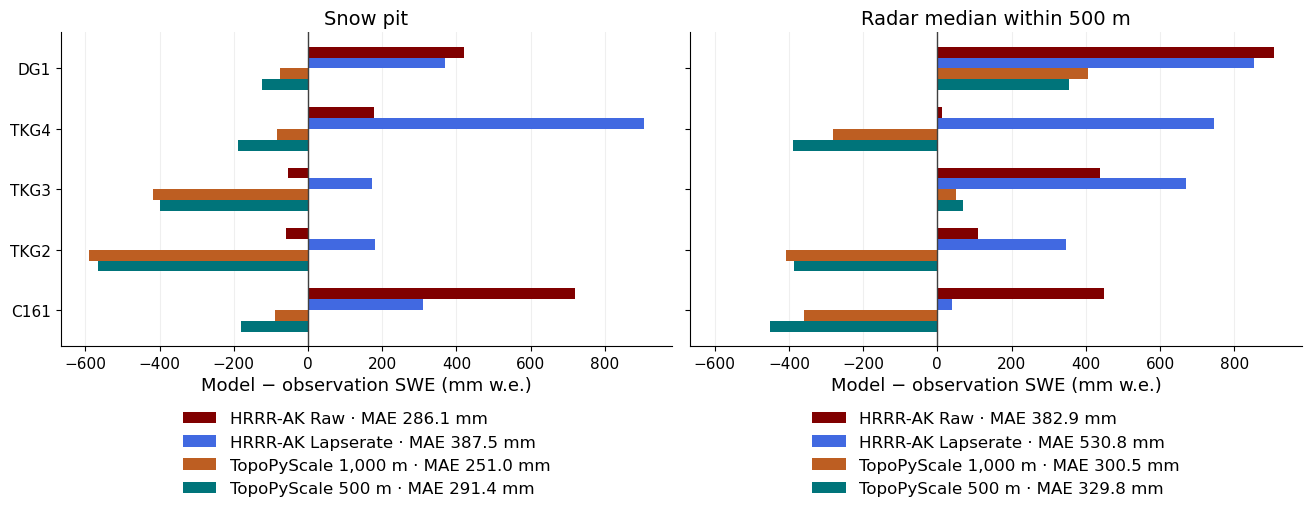

In [8]:
swe_rows = result['comparisons'].loc[
    result['comparisons'].observation.isin(['Pit SWE', 'Radar'])
].copy()
swe_rows['difference_mm'] = swe_rows.model_swe_mean_mm - swe_rows.observed_swe_mm

fig_swe_error, swe_axes = plt.subplots(
    1, 2, figsize=(13, 5), sharex=True, sharey=True, layout='constrained'
)
for ax, source, title in zip(
    swe_axes, ('Pit SWE', 'Radar'), ('Snow pit', f'Radar median within {RADIUS_M} m')
):
    source_rows = swe_rows.loc[swe_rows.observation.eq(source)]
    for offset, forcing in zip((np.arange(len(FORCINGS)) - (len(FORCINGS) - 1) / 2) * bar_height, FORCINGS):
        differences = (source_rows.loc[source_rows.forcing.eq(forcing)]
                       .set_index('site').difference_mm.reindex(SITES))
        mae = differences.abs().mean()
        ax.barh(positions + offset, differences, height=bar_height,
                color=colors[forcing], label=f'{labels[forcing]} · MAE {mae:.1f} mm')
    ax.axvline(0, color='0.25', lw=1)
    ax.set(title=title, xlabel='Model − observation SWE (mm w.e.)',
           yticks=positions, yticklabels=[site.upper() for site in SITES])
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.16), frameon=False)

swe_axes[0].invert_yaxis()
plt.show()


## Observation windows and WY2021 baseline audit

In [9]:
display(result['comparisons'].round(2))
display(result['baselines'].query('water_year == 2021').round(2))

,site,forcing,observation,start_UTC,end_exclusive_UTC,date_basis,observation_count,expected_model_hours,model_hours,complete,observed_depth_cm,observed_swe_mm,radar_depth_p10_cm,radar_depth_p90_cm,model_total_depth_mean_cm,model_adjusted_depth_mean_cm,model_depth_min_cm,model_depth_max_cm,model_swe_mean_mm
0,tkg2,hrrrak,Pit depth,2021-07-15,2021-07-16,Archived pit dig/sample date,1,24,24,True,360.00,NaN,NaN,NaN,368.79,368.79,367.91,370.64,2027.14
1,tkg2,hrrrak,Pit SWE,2021-07-15,2021-07-16,Archived pit dig/sample date,1,24,24,True,NaN,2086.10,NaN,NaN,368.79,368.79,367.91,370.64,2027.14
2,tkg2,hrrrak,Radar,2021-07-09,2021-07-16,Campaign window; exact radar date unresolved,1340,168,168,True,358.87,1972.73,278.73,379.25,379.76,379.76,367.91,394.79,2081.25
3,tkg2,hrrrak_lapserate,Pit depth,2021-07-15,2021-07-16,Archived pit dig/sample date,1,24,24,True,360.00,NaN,NaN,NaN,412.17,394.39,411.15,413.80,2266.26
4,tkg2,hrrrak_lapserate,Pit SWE,2021-07-15,2021-07-16,Archived pit dig/sample date,1,24,24,True,NaN,2086.10,NaN,NaN,412.17,394.39,411.15,413.80,2266.26
5,tkg2,hrrrak_lapserate,Radar,2021-07-09,2021-07-16,Campaign window; exact radar date unresolved,1340,168,168,True,358.87,1972.73,278.73,379.25,422.61,404.83,411.15,437.19,2318.08
6,tkg2,topopyscale_1000m,Pit depth,2021-07-15,2021-07-16,Archived pit dig/sample date,1,24,24,True,360.00,NaN,NaN,NaN,271.95,271.95,271.04,273.40,1494.76
7,tkg2,topopyscale_1000m,Pit SWE,2021-07-15,2021-07-16,Archived pit dig/sample date,1,24,24,True,NaN,2086.10,NaN,NaN,271.95,271.95,271.04,273.40,1494.76
8,tkg2,topopyscale_1000m,Radar,2021-07-09,2021-07-16,Campaign window; exact radar date unresolved,1340,168,168,True,358.87,1972.73,278.73,379.25,285.45,285.45,271.04,304.18,1564.17
9,tkg2,topopyscale_500m,Pit depth,2021-07-15,2021-07-16,Archived pit dig/sample date,1,24,24,True,360.00,NaN,NaN,NaN,276.72,276.72,275.68,278.19,1519.82


,site,forcing,water_year,autumn_minimum_cm,minimum_date,expected_hours,available_hours,complete
1,tkg2,hrrrak,2021,0.00,2020-08-31 15:00:00,2208,2208,True
8,tkg2,hrrrak_lapserate,2021,17.78,2020-09-20 11:00:00,2208,2208,True
15,tkg2,topopyscale_1000m,2021,0.00,2020-08-31 15:00:00,2208,2208,True
17,tkg2,topopyscale_500m,2021,0.00,2020-08-31 15:00:00,2208,2208,True
19,tkg3,hrrrak,2021,0.00,2020-08-31 13:00:00,2208,2208,True
26,tkg3,hrrrak_lapserate,2021,14.56,2020-09-20 11:00:00,2208,2208,True
33,tkg3,topopyscale_1000m,2021,0.00,2020-08-31 13:00:00,2208,2208,True
35,tkg3,topopyscale_500m,2021,0.00,2020-08-31 13:00:00,2208,2208,True
37,c161,hrrrak,2021,112.00,2020-09-20 11:00:00,2208,2208,True
44,c161,hrrrak_lapserate,2021,62.50,2020-09-20 09:00:00,2208,2208,True
